In this notebook we check how good the sales forecasts are. We test on the last 4 weeks of the data, one week (7 days) at a time, because our forecast horizon is 7 days. We compare Ayesha's models with two simple baselines, so we can see if the models are really better than a simple guess.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig_folder = '../outputs/figures_eval'
table_folder = '../outputs/tables'
os.makedirs(fig_folder, exist_ok=True)
os.makedirs(table_folder, exist_ok=True)

test_end = '2017-08-15'
n_blocks = 4

We load only the columns we need: the keys, the real sales, and two past sales columns that we use as simple baselines.

In [2]:
# load data
columns = ['date', 'store_nbr', 'family', 'sales', 'sales_lag_7d', 'sales_same_dow_mean_4w']
df = pd.read_parquet('../data/processed/features_engineered.parquet', columns=columns)

if str(df['date'].dtype).startswith('int'):
    df['date'] = pd.to_datetime(df['date'], unit='ms')
else:
    df['date'] = pd.to_datetime(df['date'])
df['family'] = df['family'].astype(str)
df['store_nbr'] = df['store_nbr'].astype(int)

print('rows:', len(df))
print('dates:', df['date'].min().date(), 'to', df['date'].max().date())

rows: 3000888
dates: 2013-01-01 to 2017-08-15


The test period is the last 4 weeks. Each week is a separate test block. Block 1 is the oldest week and block 4 is the last week.

In [3]:
# test blocks
end = pd.Timestamp(test_end)
start = end - pd.Timedelta(days=7 * n_blocks - 1)
test = df[(df['date'] >= start) & (df['date'] <= end)].copy()

test['block'] = n_blocks - (end - test['date']).dt.days // 7

print('test dates:', start.date(), 'to', end.date())
test.groupby('block')['date'].agg(['min', 'max', 'count'])

test dates: 2017-07-19 to 2017-08-15


,min,max,count
block,,,
1,2017-07-19,2017-07-25,12474
2,2017-07-26,2017-08-01,12474
3,2017-08-02,2017-08-08,12474
4,2017-08-09,2017-08-15,12474


Two simple baselines. The first one says sales will be the same as on the same day last week. The second one uses the average of the same weekday in the last 4 weeks. Both only use sales that are at least 7 days old, so they are fair 7-day forecasts.

In [4]:
# baselines
test['pred_last_week'] = test['sales_lag_7d']
test['pred_4week_avg'] = test['sales_same_dow_mean_4w']

print('missing last_week:', test['pred_last_week'].isna().sum())
print('missing 4week_avg:', test['pred_4week_avg'].isna().sum())

missing last_week: 0
missing 4week_avg: 0


The metrics. RMSE is the normal error in units sold. RMSLE is the error on log scale, so big and small families count more equally (this is the Kaggle metric). R2 shows how much of the change in sales the model explains (1 is perfect). MAPE divides by the real sales, so it breaks on days with zero sales. So we only use rows with sales above 0 for MAPE, and we also report WAPE (total error / total sales), which works with zeros.

In [5]:
# metrics
def rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred) ** 2))

def rmsle(actual, pred):
    pred = np.clip(pred, 0, None)
    return np.sqrt(np.mean((np.log1p(actual) - np.log1p(pred)) ** 2))

def mape(actual, pred):
    keep = actual > 0
    return 100 * np.mean(np.abs(actual[keep] - pred[keep]) / actual[keep])

def wape(actual, pred):
    return 100 * np.sum(np.abs(actual - pred)) / np.sum(actual)

def r2(actual, pred):
    return 1 - np.sum((actual - pred) ** 2) / np.sum((actual - actual.mean()) ** 2)

def get_metrics(actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)
    result = {}
    result['RMSLE'] = rmsle(actual, pred)
    result['RMSE'] = rmse(actual, pred)
    result['MAPE %'] = mape(actual, pred)
    result['WAPE %'] = wape(actual, pred)
    result['R2'] = r2(actual, pred)
    return result

Here we add Ayesha's predictions. Her file should have date, store_nbr, family and one column per model, with names starting with pred_ (for example pred_regression and pred_xgboost). If her predictions are log1p(sales), set in_log to True so they are changed back to normal sales. Until the file exists, only the baselines are scored.

In [6]:
# model predictions
pred_file = '../outputs/predictions/model_predictions.csv'
in_log = False

if os.path.exists(pred_file):
    preds = pd.read_csv(pred_file, parse_dates=['date'])
    preds['family'] = preds['family'].astype(str)
    preds['store_nbr'] = preds['store_nbr'].astype(int)

    model_cols = []
    for col in preds.columns:
        if col.startswith('pred_'):
            model_cols.append(col)

    if in_log:
        for col in model_cols:
            preds[col] = np.expm1(preds[col])

    test = test.drop(columns=model_cols, errors='ignore')
    test = test.merge(preds[['date', 'store_nbr', 'family'] + model_cols],
                      on=['date', 'store_nbr', 'family'], how='left')
    print('model predictions added:', model_cols)
else:
    print('no model predictions yet, only the baselines are scored')

no model predictions yet, only the baselines are scored


We score every model on each test block and then take the average over the 4 blocks. All models are scored on the same rows, so the comparison is fair.

In [7]:
models = []
for col in test.columns:
    if col.startswith('pred_'):
        models.append(col)

scored = test.dropna(subset=models)
print('rows scored:', len(scored), 'of', len(test))

rows = []
for model in models:
    for block in sorted(scored['block'].unique()):
        part = scored[scored['block'] == block]
        r = get_metrics(part['sales'], part[model])
        r['model'] = model.replace('pred_', '')
        r['block'] = block
        rows.append(r)

by_block = pd.DataFrame(rows)

summary = by_block.groupby('model')[['RMSLE', 'RMSE', 'MAPE %', 'WAPE %', 'R2']].mean()
summary = summary.sort_values('RMSLE')
summary.round(3)

rows scored: 49896 of 49896


,RMSLE,RMSE,MAPE %,WAPE %,R2
model,,,,,
4week_avg,0.467,254.656,39.519,15.609,0.958
last_week,0.546,309.842,47.267,18.528,0.939


RMSLE for each week separately. This shows if a model is good in every week or only on average.

In [8]:
by_block.pivot(index='block', columns='model', values='RMSLE').round(3)

model,4week_avg,last_week
block,,
1,0.430,0.506
2,0.460,0.550
3,0.500,0.582
4,0.476,0.546


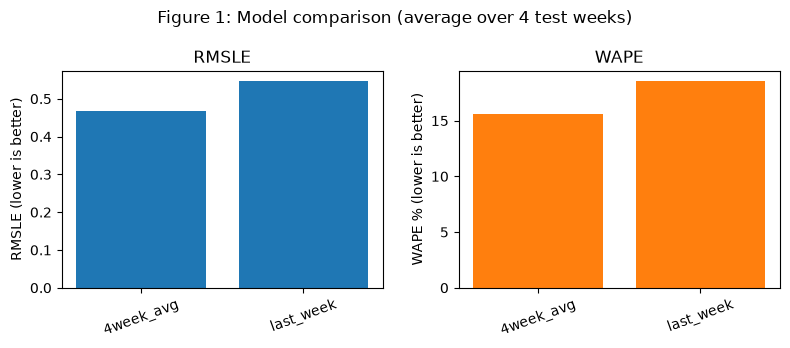

In [9]:
x = np.arange(len(summary))

plt.figure(figsize=(8, 3.5))
plt.subplot(1, 2, 1)
plt.bar(x, summary['RMSLE'], color='#1f77b4')
plt.xticks(x, summary.index, rotation=20)
plt.ylabel('RMSLE (lower is better)')
plt.title('RMSLE')

plt.subplot(1, 2, 2)
plt.bar(x, summary['WAPE %'], color='#ff7f0e')
plt.xticks(x, summary.index, rotation=20)
plt.ylabel('WAPE % (lower is better)')
plt.title('WAPE')

plt.suptitle('Figure 1: Model comparison (average over 4 test weeks)')
plt.tight_layout()
plt.savefig(fig_folder + '/fig1_model_comparison.png')
plt.show()

Where does the best model fail? We look at the error (WAPE) for each family, together with how much of total sales that family makes. A big error in a small family matters less than in GROCERY I or BEVERAGES.

In [10]:
best = 'pred_' + summary.index[0]
print('best model:', summary.index[0])

rows = []
for fam in sorted(scored['family'].unique()):
    part = scored[scored['family'] == fam]
    if part['sales'].sum() == 0:
        continue
    rows.append({'family': fam,
                 'WAPE %': wape(part['sales'].values, np.clip(part[best].values, 0, None)),
                 'share of sales %': 100 * part['sales'].sum() / scored['sales'].sum()})

by_family = pd.DataFrame(rows).set_index('family').sort_values('WAPE %')
by_family.round(2)

best model: 4week_avg


,WAPE %,share of sales %
family,,
PRODUCE,9.74,14.82
DAIRY,11.84,5.43
BREAD/BAKERY,12.18,3.44
GROCERY I,13.09,29.47
POULTRY,13.34,2.46
MEATS,13.62,2.43
DELI,14.47,1.96
BEVERAGES,16.65,22.84
PREPARED FOODS,17.20,0.57


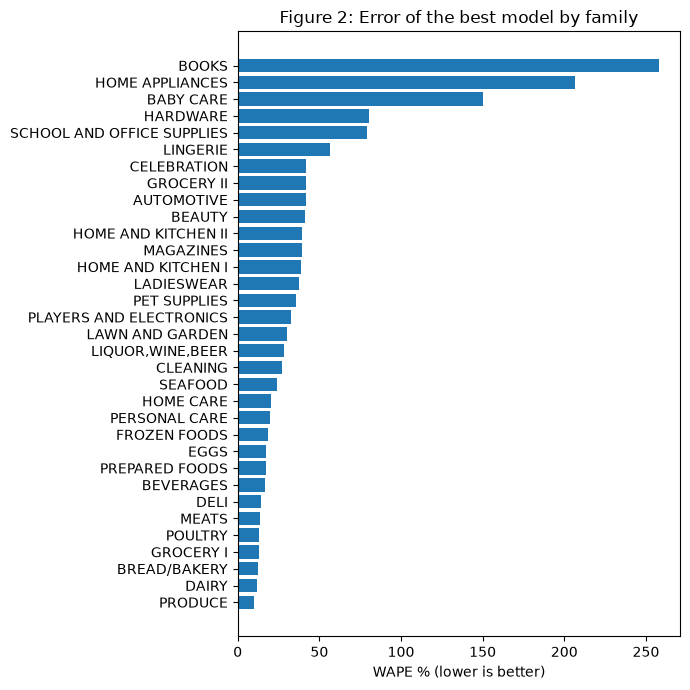

In [11]:
plt.figure(figsize=(7, 7))
plt.barh(by_family.index, by_family['WAPE %'], color='#1f77b4')
plt.xlabel('WAPE % (lower is better)')
plt.title('Figure 2: Error of the best model by family')
plt.tight_layout()
plt.savefig(fig_folder + '/fig2_error_by_family.png')
plt.show()

We save the tables so they can be used in the report.

In [12]:
# save tables
summary.to_csv(table_folder + '/eval_summary.csv')
by_block.to_csv(table_folder + '/eval_by_block.csv', index=False)
by_family.to_csv(table_folder + '/eval_error_by_family.csv')
print('tables saved in', table_folder)
print('figures saved in', fig_folder)

tables saved in ../outputs/tables
figures saved in ../outputs/figures_eval
